# 4.6 Phân khúc khách hàng (Customer Segments) — Online Retail II

Nguồn của frame *Customer segments* trên slide và Mục 4.6 của report: chia khách thành 8 nhóm theo R, F, M trên **toàn bộ lịch sử** của mỗi khách, rồi gộp Cooling, Lapsed và Dormant thành **Inactive** (6 nhóm).

**Đầu vào:** `data/raw/online_retail_II.parquet`, làm sạch ngay trong notebook: giữ dòng có Customer ID, bỏ dòng trùng, bỏ mã không phải sản phẩm (StockCode không bắt đầu bằng chữ số, cùng quy tắc với notebook 03) và giữ Price > 0. Hóa đơn bắt đầu bằng `C` là hàng trả, được trừ vào M.

**Notebook này chỉ để mô tả:** không dùng cutoff cố định, không dùng cửa sổ quan sát, không có nhãn tương lai, và không đưa vào model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)

raw = pd.read_parquet("../data/raw/online_retail_II.parquet")
clean = raw.dropna(subset=["Customer ID"]).drop_duplicates()
clean = clean[clean["StockCode"].astype(str).str[:1].str.isdigit() & (clean["Price"] > 0)]
clean = pd.DataFrame({
    "Invoice": clean["Invoice"].astype(str),
    "InvoiceDate": clean["InvoiceDate"],
    "Revenue": clean["Quantity"] * clean["Price"],
    "CustomerID": clean["Customer ID"].astype(int),
})
clean["is_return"] = clean["Invoice"].str.startswith("C")
first_seen = clean.groupby("CustomerID")["InvoiceDate"].min()

DATA_START = clean["InvoiceDate"].min().normalize()
END = clean["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)   # the day after the last transaction
print(f"{len(clean):,} rows | {clean['CustomerID'].nunique():,} customers | {DATA_START.date()} to {END.date()} (exclusive)")

SEGMENTS = ["Champions", "VIP at risk", "Loyal", "Developing", "One-time recent", "Cooling", "Lapsed", "Dormant"]
T = {"recency_active": 90, "recency_lapsed": 180, "recency_dormant": 365, "freq_repeat": 2, "freq_loyal": 4}

def assign_segment(r, monetary_high):
    high_value = r["monetary"] >= monetary_high
    active = r["recency_days"] <= T["recency_active"]
    conditions = [
        high_value & active,
        high_value,
        active & (r["frequency"] >= T["freq_loyal"]),
        active & (r["frequency"] >= T["freq_repeat"]),
        active,
        r["recency_days"] <= T["recency_lapsed"],
        r["recency_days"] <= T["recency_dormant"],
    ]
    seg = np.select(conditions, SEGMENTS[:-1], default=SEGMENTS[-1])
    return pd.Categorical(seg, categories=SEGMENTS, ordered=True)

794,163 rows | 5,875 customers | 2009-12-01 to 2011-12-10 (exclusive)


## 4.6.1 Đặc trưng RFM

| Đặc trưng | Định nghĩa | Lý do |
|---|---|---|
| `recency_days` (R) | Số ngày từ lần **mua** cuối đến ngày sau giao dịch cuối của dữ liệu | Hóa đơn trả hàng không tính là hoạt động mua |
| `frequency` (F) | Số hóa đơn bán khác nhau trong toàn bộ lịch sử | Khớp với mốc 1 / 2-3 / 4+ |
| `monetary` (M) | Doanh số bán trừ hàng trả trong toàn bộ lịch sử, sàn ở 0 | Hàng trả làm hao hụt giá trị thật của khách |
| `purchase_days` | Số ngày mua khác nhau | Đối chiếu với F (khách bán buôn có thể xuất nhiều hóa đơn trong một ngày) |
| `avg_order_value` | Doanh số bán / F | Phân biệt khách đơn lớn với khách đơn nhỏ |
| `return_rate` | Giá trị hàng trả / doanh số bán | Hàng trả làm hao hụt biên lợi nhuận |
| `tenure_days` | Số ngày từ lần đầu xuất hiện đến ngày tính | Khách lâu năm hay khách mới |
| `avg_gap_days` | Số ngày trung bình giữa hai ngày mua liên tiếp (rỗng nếu chỉ mua một ngày) | Nhịp mua riêng của từng khách |
| `recency_gap_ratio` | `recency_days` / `avg_gap_days` | Khách có nhịp 30 ngày mà đã 80 ngày không mua đáng lo hơn khách có nhịp 150 ngày. Tỷ số > 1 nghĩa là đã im lặng lâu hơn nhịp thường lệ |
| `frequency_90d`, `monetary_90d` | F và M chỉ tính 90 ngày cuối | Hoạt động gần đây, nhạy hơn số liệu toàn lịch sử |
| `monetary_90d_share` | `monetary_90d` / `monetary` | Khách đang tăng hay giảm hoạt động so với mức toàn lịch sử |

Các cột nhịp mua và 90 ngày **không dùng để phân nhóm**, chỉ để mô tả khách chi tiết hơn.

**Lưu ý:** vì F và M cộng dồn toàn lịch sử nên chúng chỉ tăng theo thời gian. Khách có mặt từ 2009-12 có nhiều thời gian để tích lũy hơn khách mới, nên F và M ở phần A phản ánh một phần độ dài lịch sử của khách.

In [2]:
def build_rfm(rows, ref_date):
    sales = rows[~rows["is_return"]]
    returns = rows[rows["is_return"]]
    g = sales.groupby("CustomerID")

    rfm = pd.DataFrame({
        "recency_days": (ref_date - g["InvoiceDate"].max()).dt.days,
        "frequency": g["Invoice"].nunique(),
        "purchase_days": g["InvoiceDate"].apply(lambda d: d.dt.normalize().nunique()),
        "gross_sales": g["Revenue"].sum(),
    })
    rfm["return_value"] = -returns.groupby("CustomerID")["Revenue"].sum()
    rfm["return_value"] = rfm["return_value"].fillna(0)
    rfm["monetary"] = (rfm["gross_sales"] - rfm["return_value"]).clip(lower=0)
    rfm["avg_order_value"] = rfm["gross_sales"] / rfm["frequency"]
    rfm["return_rate"] = rfm["return_value"] / rfm["gross_sales"]
    rfm["tenure_days"] = (ref_date - first_seen.reindex(rfm.index)).dt.days

    # Purchase rhythm: mean gap between distinct purchase days, and how long the customer has been silent relative to it
    days = sales.assign(day=sales["InvoiceDate"].dt.normalize()).groupby("CustomerID")["day"]
    rfm["avg_gap_days"] = (days.max() - days.min()).dt.days / (rfm["purchase_days"] - 1).replace(0, np.nan)
    rfm["recency_gap_ratio"] = rfm["recency_days"] / rfm["avg_gap_days"]

    # Short window: last 90 days before ref_date
    last90 = ref_date - pd.Timedelta(days=90)
    g90 = sales[sales["InvoiceDate"] >= last90].groupby("CustomerID")
    ret90 = returns[returns["InvoiceDate"] >= last90].groupby("CustomerID")["Revenue"].sum()
    gross90 = g90["Revenue"].sum()
    rfm["frequency_90d"] = g90["Invoice"].nunique().reindex(rfm.index).fillna(0).astype(int)
    rfm["monetary_90d"] = (gross90 + ret90.reindex(gross90.index).fillna(0)).clip(lower=0).reindex(rfm.index).fillna(0)
    rfm["monetary_90d_share"] = rfm["monetary_90d"] / rfm["monetary"].replace(0, np.nan)
    return rfm.reset_index()

rfm = build_rfm(clean, END)
assert rfm[["recency_days", "frequency", "monetary"]].notna().all().all()
print(f"{len(rfm):,} customers with at least one sale")

rfm[["recency_days", "frequency", "purchase_days", "monetary", "avg_order_value", "return_rate", "tenure_days",
     "avg_gap_days", "recency_gap_ratio", "frequency_90d", "monetary_90d", "monetary_90d_share"]] \
    .describe(percentiles=[.25, .5, .75, .9, .95, .99])

5,852 customers with at least one sale


,recency_days,frequency,purchase_days,monetary,avg_order_value,return_rate,tenure_days,avg_gap_days,recency_gap_ratio,frequency_90d,monetary_90d,monetary_90d_share
count,"5,852.00","5,852.00","5,852.00","5,852.00","5,852.00","5,852.00","5,852.00","4,179.00","4,179.00","5,852.00","5,852.00","5,833.00"
mean,199.73,6.25,5.62,"2,795.89",384.40,0.02,475.66,111.48,3.75,1.12,534.36,0.22
std,208.52,12.75,9.92,"13,825.19","1,254.73",0.10,224.35,102.34,22.37,2.51,"3,020.71",0.32
min,0.00,1.00,1.00,0.00,2.95,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,25.00,1.00,1.00,330.94,176.15,0.00,313.00,44.00,0.22,0.00,0.00,0.00
50%,95.00,3.00,3.00,840.25,277.87,0.00,532.00,80.00,0.64,0.00,0.00,0.00
75%,379.00,7.00,6.00,"2,172.03",410.56,0.01,670.00,142.00,2.14,1.00,474.06,0.30
90%,530.00,13.00,12.00,"5,224.45",624.03,0.05,731.00,238.20,6.23,3.00,"1,131.14",1.00
95%,623.00,20.00,18.45,"8,899.83",871.21,0.10,736.00,348.00,12.79,4.00,"1,849.46",1.00
99%,726.00,46.00,39.00,"26,490.31","1,907.11",0.39,738.00,513.22,37.34,9.00,"4,813.24",1.00


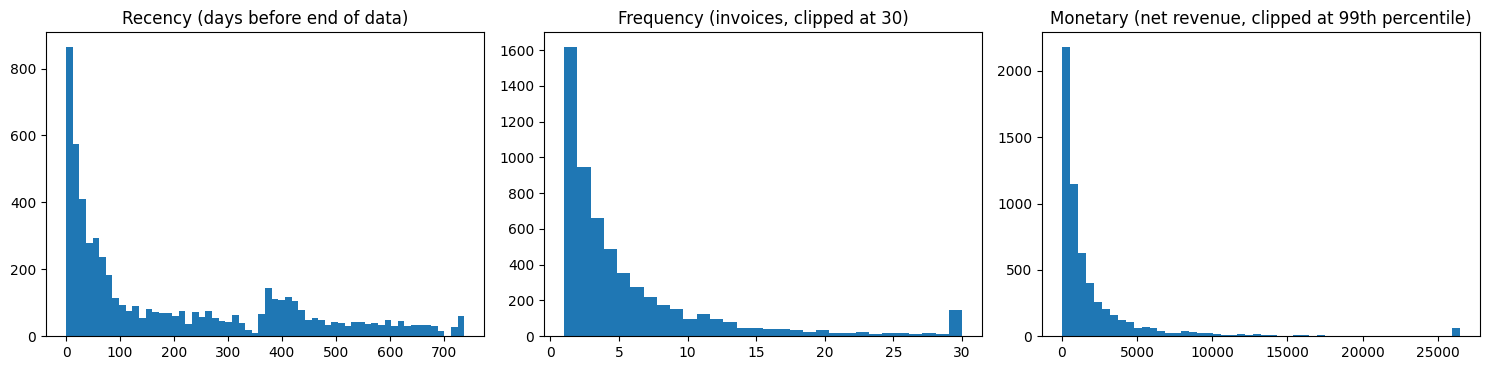

Share of customers with F != purchase_days: 20.8%


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(rfm["recency_days"], bins=60, color="tab:blue")
axes[1].hist(rfm["frequency"].clip(upper=30), bins=30, color="tab:blue")
axes[2].hist(rfm["monetary"].clip(upper=rfm["monetary"].quantile(.99)), bins=50, color="tab:blue")
axes[0].set_title("Recency (days before end of data)")
axes[1].set_title("Frequency (invoices, clipped at 30)")
axes[2].set_title("Monetary (net revenue, clipped at 99th percentile)")
plt.tight_layout(); plt.show()

print(f"Share of customers with F != purchase_days: {(rfm['frequency'] != rfm['purchase_days']).mean():.1%}")

**Ý nghĩa của "Share of customers with F != purchase_days" (20.8%):** đây là tỷ lệ khách có số hóa đơn (F) lớn hơn số ngày mua khác nhau (`purchase_days`), tức là khách có **nhiều hóa đơn trong cùng một ngày**.

* F đếm số hóa đơn; `purchase_days` đếm số ngày khác nhau có mua. Hai số bằng nhau khi mỗi ngày khách chỉ có một hóa đơn.
* Ví dụ: khách mua vào thứ Hai và có hai hóa đơn (một cho hàng khô, một cho hàng đông lạnh) thì F tăng 2 nhưng chỉ có 1 ngày mua.
* Khách bán buôn thường tách đơn như vậy (theo nhà kho hoặc theo loại hàng), nên F của họ có thể cao hơn số lần quay lại thật sự. Khách có F = 4 chưa chắc đã quay lại 4 lần.
* Notebook vẫn dùng **F theo hóa đơn** trong luật phân nhóm, để khớp với các mốc 1 / 2-3 / 4+. Cột `purchase_days` được giữ lại để đối chiếu. Nếu muốn F phản ánh số lần quay lại, có thể thay F bằng `purchase_days` trong luật; một số khách Loyal khi đó sẽ xuống Developing.

### 4.6.2 Đặt ngưỡng

Mỗi ngưỡng có một nguồn bằng chứng:
* **R:** mốc 90 ngày và 180 ngày từ mục 4.5 (71% khách có trung vị khoảng cách mua ≤ 90 ngày, 93% ≤ 180 ngày). Quá 90 ngày là khách bắt đầu "nguội", quá 180 ngày là đã vắng lâu. Mốc **365 ngày** (một năm không mua) tách khách quá 180 ngày thành hai nhóm: Lapsed (181-365) và Dormant (> 365).
* **F:** mốc 1 / 2-3 / 4+ hóa đơn.
* **M:** đường cong tập trung doanh thu (Pareto). Ngưỡng "giá trị cao" là mức doanh thu của top 10% khách.

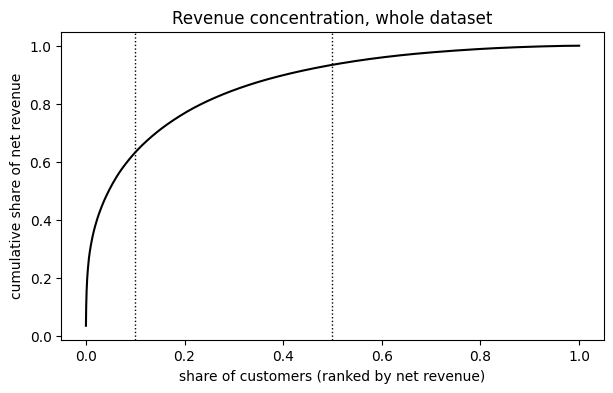

monetary_high (top 10%) = 5,224.45


,monetary_threshold,share_of_revenue
customers,,
top 1%,"26,679.24",0.31
top 5%,"8,945.53",0.51
top 10%,"5,250.78",0.63
top 20%,"2,835.36",0.77
top 30%,"1,743.15",0.85
top 50%,840.25,0.93


In [4]:
m = rfm["monetary"].sort_values(ascending=False).reset_index(drop=True)
cum_share = m.cumsum() / m.sum()
qs = (.01, .05, .10, .20, .30, .50)
pareto = pd.DataFrame({
    "monetary_threshold": [m.iloc[int(len(m) * q) - 1] for q in qs],
    "share_of_revenue": [cum_share.iloc[int(len(m) * q) - 1] for q in qs],
}, index=pd.Index(["top 1%", "top 5%", "top 10%", "top 20%", "top 30%", "top 50%"], name="customers"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(m) + 1) / len(m), cum_share, color="black")
for q in (.1, .5):
    ax.axvline(q, color="k", ls=":", lw=1)
ax.set_xlabel("share of customers (ranked by net revenue)"); ax.set_ylabel("cumulative share of net revenue")
ax.set_title("Revenue concentration, whole dataset"); plt.show()

MONETARY_HIGH = rfm["monetary"].quantile(.90)
print(f"monetary_high (top 10%) = {MONETARY_HIGH:,.2f}")
pareto

### 4.6.3 Luật phân nhóm

Các điều kiện được xét **theo thứ tự**: khách rơi vào điều kiện đầu tiên đúng. Nhờ vậy các nhóm loại trừ nhau và phủ hết mọi khách (8 nhóm).

| # | Nhóm | Điều kiện | Ý nghĩa |
|---|---|---|---|
| 1 | Champions | M ≥ top 10% **và** R ≤ 90 | Giá trị cao nhất, đang hoạt động |
| 2 | VIP at risk | M ≥ top 10% **và** R > 90 | Từng giá trị cao nhưng đã lâu không mua |
| 3 | Loyal | R ≤ 90 **và** F ≥ 4 | Mua đều, giá trị vừa |
| 4 | Developing | R ≤ 90 **và** F = 2-3 | Đã mua lại, chưa thành thói quen |
| 5 | One-time recent | R ≤ 90 **và** F = 1 | Mới mua một lần gần đây |
| 6 | Cooling | 90 < R ≤ 180 | Đang nguội |
| 7 | Lapsed | 180 < R ≤ 365 | Đã vắng lâu nhưng còn cơ hội kéo lại |
| 8 | Dormant | R > 365 | Gần như đã rời đi |

In [5]:
rfm["segment"] = assign_segment(rfm, MONETARY_HIGH)
assert rfm["segment"].notna().all()

rfm["segment"].value_counts().reindex(SEGMENTS).rename("customers").to_frame()

,customers
segment,
Champions,515
VIP at risk,71
Loyal,1345
Developing,658
One-time recent,367
Cooling,555
Lapsed,777
Dormant,1564


### 4.6.4 Hồ sơ nhóm

Với mỗi nhóm: quy mô, đặc điểm (R, F, M, trả hàng, nhịp mua) và phần đóng góp vào doanh thu.

In [6]:
profile = rfm.groupby("segment", observed=False).agg(
    customers=("CustomerID", "size"),
    median_recency=("recency_days", "median"),
    median_frequency=("frequency", "median"),
    median_monetary=("monetary", "median"),
    mean_monetary=("monetary", "mean"),
    median_return_rate=("return_rate", "median"),
    median_avg_gap_days=("avg_gap_days", "median"),
    median_monetary_90d=("monetary_90d", "median"),
    total_monetary=("monetary", "sum"),
)
profile.insert(1, "share_customers", profile["customers"] / profile["customers"].sum())
profile["share_revenue"] = profile.pop("total_monetary") / rfm["monetary"].sum()
profile

,customers,share_customers,median_recency,median_frequency,median_monetary,mean_monetary,median_return_rate,median_avg_gap_days,median_monetary_90d,share_revenue
segment,,,,,,,,,,
Champions,515,0.09,11.00,20.00,"8,945.53","18,449.45",0.01,37.53,"1,551.72",0.58
VIP at risk,71,0.01,184.00,13.00,"8,550.92","11,978.52",0.01,43.02,0.00,0.05
Loyal,1345,0.23,24.00,7.00,"2,070.71","2,294.74",0.00,79.44,474.02,0.19
Developing,658,0.11,29.00,2.00,663.66,805.98,0.00,164.75,347.52,0.03
One-time recent,367,0.06,44.00,1.00,256.32,368.84,0.00,NaN,256.32,0.01
Cooling,555,0.09,131.00,3.00,868.77,"1,241.88",0.00,106.70,0.00,0.04
Lapsed,777,0.13,260.00,2.00,566.13,870.61,0.00,107.67,0.00,0.04
Dormant,1564,0.27,468.00,1.00,338.56,570.21,0.00,74.50,0.00,0.05


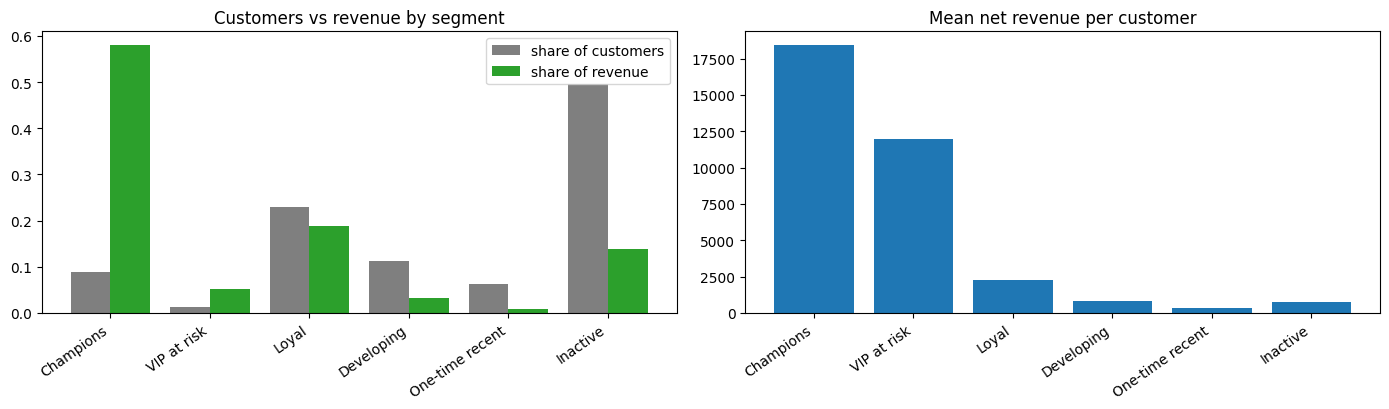

Champions + VIP at risk (top 10% spenders): 10.0% of customers, 63.3% of revenue


,customers,share_customers,share_revenue,mean_monetary
segment,,,,
Champions,515,8.8%,58.1%,"18,449.45"
VIP at risk,71,1.2%,5.2%,"11,978.52"
Loyal,1345,23.0%,18.9%,"2,294.74"
Developing,658,11.2%,3.2%,805.98
One-time recent,367,6.3%,0.8%,368.84
Inactive,2896,49.5%,13.8%,779.53


In [7]:
# Cooling, Lapsed and Dormant are merged into one "Inactive" group; the other five segments stay as they are
MERGED = SEGMENTS[:5] + ["Inactive"]
seg_merged = rfm["segment"].astype(str).where(rfm["segment"].isin(SEGMENTS[:5]), "Inactive")
prof_m = rfm.groupby(seg_merged).agg(customers=("CustomerID", "size"), mean_monetary=("monetary", "mean"),
                                     total_monetary=("monetary", "sum")).reindex(MERGED)
prof_m["share_customers"] = prof_m["customers"] / prof_m["customers"].sum()
prof_m["share_revenue"] = prof_m["total_monetary"] / prof_m["total_monetary"].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(MERGED))
axes[0].bar(x - .2, prof_m["share_customers"], width=.4, color="tab:gray", label="share of customers")
axes[0].bar(x + .2, prof_m["share_revenue"], width=.4, color="tab:green", label="share of revenue")
axes[0].set_title("Customers vs revenue by segment")
axes[1].bar(x, prof_m["mean_monetary"], color="tab:blue")
axes[1].set_title("Mean net revenue per customer")
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(MERGED, rotation=35, ha="right")
axes[0].legend()
plt.tight_layout()
fig.savefig("../report/figures/ch4_customer_segments.png", dpi=150, bbox_inches="tight")
plt.show()

top_value = prof_m.loc[["Champions", "VIP at risk"]]
print(f"Champions + VIP at risk (top 10% spenders): {top_value.share_customers.sum():.1%} of customers, "
      f"{top_value.share_revenue.sum():.1%} of revenue")
prof_m.assign(share_customers=prof_m["share_customers"].map("{:.1%}".format),
              share_revenue=prof_m["share_revenue"].map("{:.1%}".format))[
    ["customers", "share_customers", "share_revenue", "mean_monetary"]]